# Lab 4: Logistic Regression & Naive Bayes

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NgKhiem69/datascience_course/blob/main/labs/04-logistic-regression/Logistic%20Regression.ipynb)

**Nội dung:**
1. Logistic Regression — dự đoán đậu/rớt từ dữ liệu sinh viên (`student_performance_prediction.csv`).
2. Minh hoạ trực quan đường sigmoid với `studyhours.csv`.
3. Naive Bayes — phân loại email spam (`spam_or_not_spam.csv`).
4. Đánh giá mô hình: accuracy, confusion matrix, precision/recall/F1, ROC-AUC.

## 0. Thiết lập môi trường (Google Colab)

Dữ liệu được đọc trực tiếp từ thư mục `data/` của repo GitHub qua đường dẫn *raw*, nên không cần upload file hay mount Google Drive.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Đường dẫn raw tới thư mục data trên GitHub
GITHUB_USER, GITHUB_REPO, BRANCH = "NgKhiem69", "datascience_course", "main"
DATA_URL = f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}/{BRANCH}/data"

def data_path(filename):
    """Trả về URL raw của một file trong thư mục data/ của repo."""
    return f"{DATA_URL}/{filename}"

# Kiểm tra đang chạy trên Colab hay máy local
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running on Colab:", IN_COLAB)
print("Data URL:", DATA_URL)

Running on Colab: False
Data URL: https://raw.githubusercontent.com/NgKhiem69/datascience_course/main/data


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score)

RANDOM_STATE = 42

# Phần 1. Logistic Regression

## 1.1 Đọc dữ liệu

In [3]:
exam_df = pd.read_csv(data_path("student_performance_prediction.csv"))
print("Shape:", exam_df.shape)
exam_df.head()

Shape: (40000, 7)


,Student ID,Study Hours per Week,Attendance Rate,Previous Grades,Participation in Extracurricular Activities,Parent Education Level,Passed
0,S00001,12.5,NaN,75.0,Yes,Master,Yes
1,S00002,9.3,95.3,60.6,No,High School,No
2,S00003,13.2,NaN,64.0,No,Associate,No
3,S00004,17.6,76.8,62.4,Yes,Bachelor,No
4,S00005,8.8,89.3,72.7,No,Master,No


## 1.2 Exploratory Data Analysis

In [4]:
exam_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 7 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Student ID                                   40000 non-null  str    
 1   Study Hours per Week                         38005 non-null  float64
 2   Attendance Rate                              38008 non-null  float64
 3   Previous Grades                              38006 non-null  float64
 4   Participation in Extracurricular Activities  38000 non-null  str    
 5   Parent Education Level                       38000 non-null  str    
 6   Passed                                       38000 non-null  str    
dtypes: float64(3), str(4)
memory usage: 2.1 MB


In [5]:
exam_df.describe()

,Study Hours per Week,Attendance Rate,Previous Grades
count,38005.000000,38008.000000,38006.000000
mean,9.962744,75.276323,65.440107
std,5.031154,20.393418,16.503119
min,-12.300000,-14.300000,8.300000
25%,6.600000,61.600000,55.100000
50%,10.000000,75.300000,65.200000
75%,13.400000,88.800000,75.200000
max,32.400000,150.200000,200.000000


In [6]:
# Số giá trị thiếu ở mỗi cột
print(exam_df.isna().sum())

Student ID                                        0
Study Hours per Week                           1995
Attendance Rate                                1992
Previous Grades                                1994
Participation in Extracurricular Activities    2000
Parent Education Level                         2000
Passed                                         2000
dtype: int64


**Nhận xét:** mỗi cột có khoảng 5% giá trị thiếu. Ngoài ra `describe()` cho thấy có giá trị **bất hợp lệ**: số giờ học âm, tỉ lệ chuyên cần âm hoặc > 100%, điểm trước đó > 100.

## 1.3 Làm sạch dữ liệu

In [7]:
n_before = len(exam_df)

# 1) Xoá các dòng thiếu giá trị
exam_df = exam_df.dropna()

# 2) Xoá các giá trị nằm ngoài miền hợp lệ
valid = (
    exam_df["Study Hours per Week"].between(0, 168)
    & exam_df["Attendance Rate"].between(0, 100)
    & exam_df["Previous Grades"].between(0, 100)
)
print("Số dòng bất hợp lệ:", (~valid).sum())
exam_df = exam_df[valid].copy()

print(f"Còn lại {len(exam_df)}/{n_before} dòng")
exam_df.describe()

Số dòng bất hợp lệ: 4197
Còn lại 25249/40000 dòng


,Study Hours per Week,Attendance Rate,Previous Grades
count,25249.000000,25249.000000,25249.000000
mean,10.249947,71.007862,64.678910
std,4.706202,16.799869,14.538508
min,-0.000000,0.500000,8.300000
25%,6.900000,59.800000,54.800000
50%,10.100000,72.500000,65.000000
75%,13.400000,84.000000,74.700000
max,32.400000,100.000000,100.000000


In [8]:
# Mã hoá nhãn: Passed = Yes → 1, No → 0
exam_df["Label"] = (exam_df["Passed"] == "Yes").astype(int)
print(exam_df["Label"].value_counts(normalize=True).round(3))
exam_df.head()

Label
0    0.504
1    0.496
Name: proportion, dtype: float64


,Student ID,Study Hours per Week,Attendance Rate,Previous Grades,Participation in Extracurricular Activities,Parent Education Level,Passed,Label
1,S00002,9.3,95.3,60.6,No,High School,No,0
3,S00004,17.6,76.8,62.4,Yes,Bachelor,No,0
4,S00005,8.8,89.3,72.7,No,Master,No,0
5,S00006,8.8,73.8,69.3,Yes,High School,Yes,1
6,S00007,17.9,38.6,93.6,No,Doctorate,Yes,1


Hai lớp gần như cân bằng (~50/50), nên **mô hình đoán bừa đã đạt ~50% accuracy**. Đây là mốc (baseline) để so sánh.

### Trực quan: các đặc trưng có khác nhau giữa nhóm đậu và rớt?

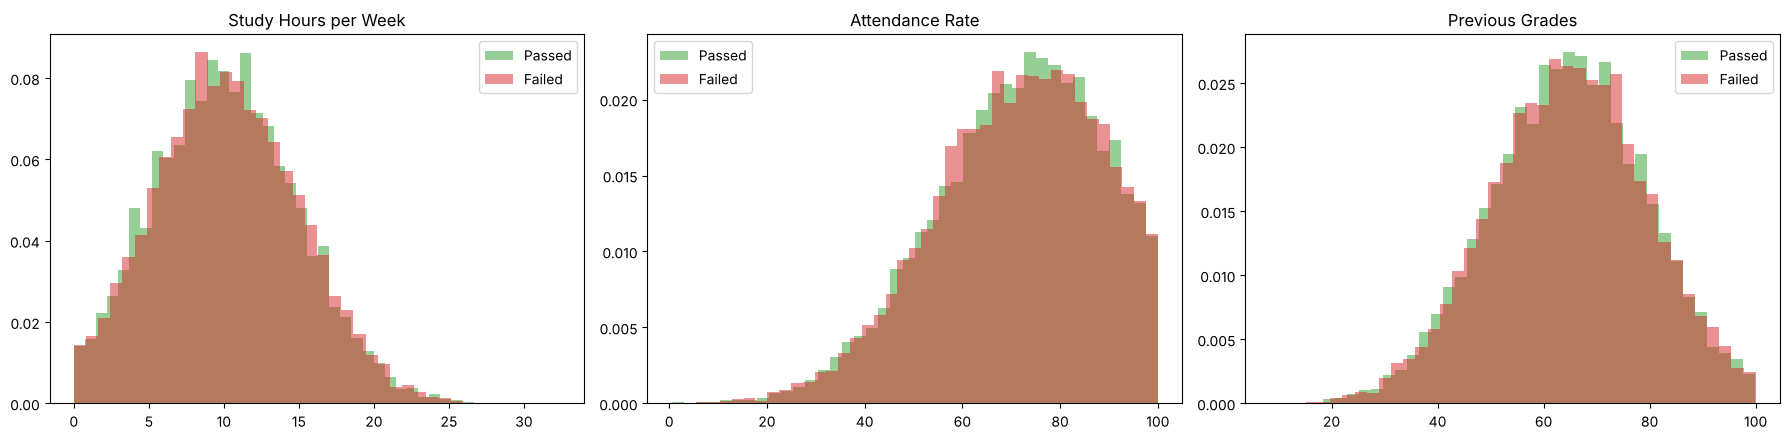

,Study Hours per Week,Attendance Rate,Previous Grades
Passed,,,
No,10.31,70.97,64.72
Yes,10.19,71.05,64.64


In [9]:
num_cols = ["Study Hours per Week", "Attendance Rate", "Previous Grades"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, num_cols):
    for label, color, name in [(1, "#2ca02c", "Passed"), (0, "#d62728", "Failed")]:
        ax.hist(exam_df.loc[exam_df["Label"] == label, col], bins=40, alpha=0.5,
                color=color, label=name, density=True)
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

exam_df.groupby("Passed")[num_cols].mean().round(2)

## 1.4 Mô hình 1 biến: Study Hours per Week → Passed

In [10]:
X = exam_df[["Study Hours per Week"]].to_numpy()   # shape (n, 1)
y = exam_df["Label"].to_numpy()
print(X.shape, y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)

(25249, 1) (25249,)
Train: (20199, 1) (20199,)
Test : (5050, 1) (5050,)


In [11]:
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(X_train, y_train)
print(f"Accuracy on test set: {clf.score(X_test, y_test):.4f}")

proba = clf.predict_proba(X_test[:5])[:, 1]
print("P(pass) 5 mẫu đầu:", proba.round(3))
print("Nhãn thật         :", y_test[:5])

lr = clf.named_steps["logisticregression"]
print(f"Hệ số w = {lr.coef_[0][0]:.4f}, bias b = {lr.intercept_[0]:.4f}")

Accuracy on test set: 0.4992
P(pass) 5 mẫu đầu: [0.494 0.499 0.502 0.491 0.495]
Nhãn thật         : [1 1 0 0 0]
Hệ số w = -0.0312, bias b = -0.0142


## 1.5 Mô hình nhiều biến

Dùng tất cả các đặc trưng: 3 cột số được chuẩn hoá (`StandardScaler`), 2 cột phân loại được mã hoá one-hot (`OneHotEncoder`).

In [12]:
feature_cols = num_cols + ["Participation in Extracurricular Activities", "Parent Education Level"]
cat_cols = ["Participation in Extracurricular Activities", "Parent Education Level"]

X_all = exam_df[feature_cols]
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
full_clf = make_pipeline(preprocess, LogisticRegression(max_iter=1000))
full_clf.fit(X_train, y_train)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

y_pred = full_clf.predict(X_test)
y_proba = full_clf.predict_proba(X_test)[:, 1]
print(f"Baseline (đoán lớp nhiều nhất): {baseline.score(X_test, y_test):.4f}")
print(f"Logistic Regression accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC                       : {roc_auc_score(y_test, y_proba):.4f}")

cv = cross_val_score(full_clf, X_all, y, cv=5, scoring="accuracy")
print(f"5-fold CV accuracy: {cv.mean():.4f} ± {cv.std():.4f}")

Baseline (đoán lớp nhiều nhất): 0.5036
Logistic Regression accuracy  : 0.5048
ROC-AUC                       : 0.5063


5-fold CV accuracy: 0.4998 ± 0.0041


              precision    recall  f1-score   support

        Fail      0.507     0.608     0.553      2543
        Pass      0.501     0.400     0.445      2507

    accuracy                          0.505      5050
   macro avg      0.504     0.504     0.499      5050
weighted avg      0.504     0.505     0.499      5050



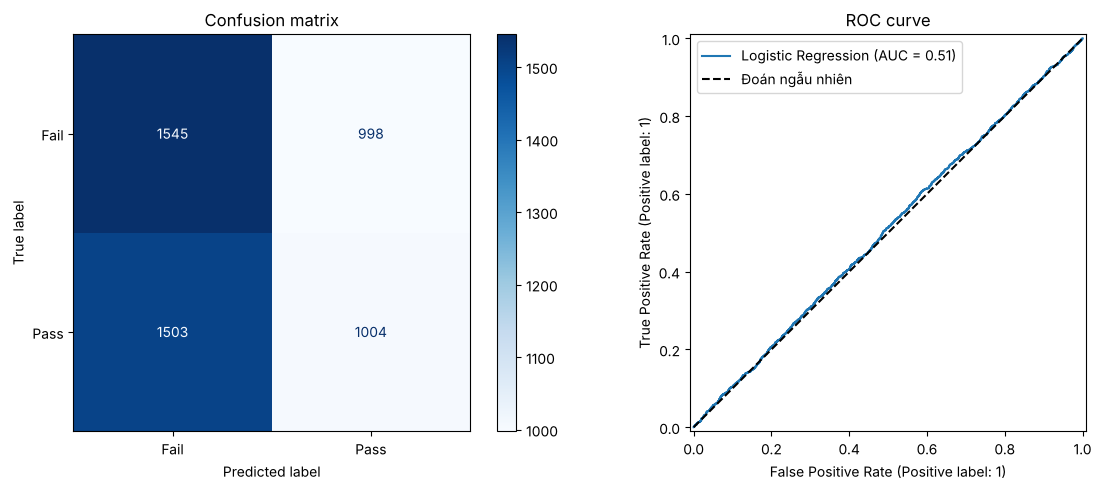

In [13]:
print(classification_report(y_test, y_pred, target_names=["Fail", "Pass"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Fail", "Pass"],
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion matrix")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name="Logistic Regression")
axes[1].plot([0, 1], [0, 1], "k--", label="Đoán ngẫu nhiên")
axes[1].legend()
axes[1].set_title("ROC curve")
plt.tight_layout()
plt.show()

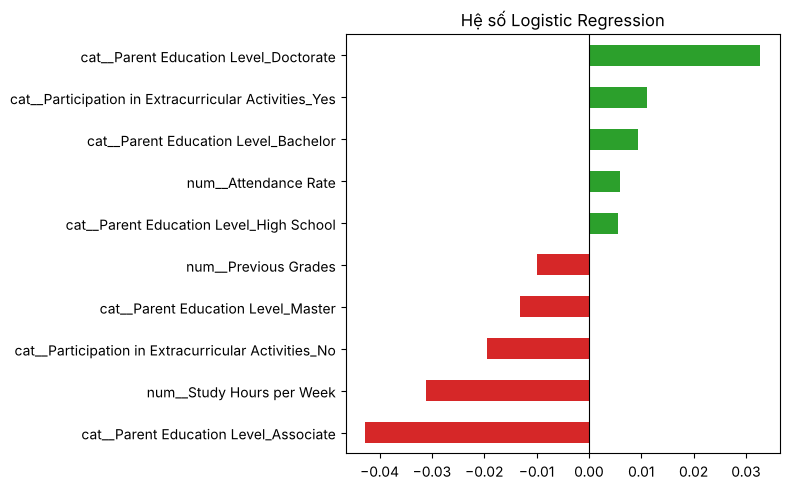

In [14]:
# Trọng số của từng đặc trưng (sau chuẩn hoá) — trị tuyệt đối càng lớn, ảnh hưởng càng mạnh
names = full_clf.named_steps["columntransformer"].get_feature_names_out()
coefs = pd.Series(full_clf.named_steps["logisticregression"].coef_[0], index=names).sort_values()
coefs.plot.barh(figsize=(8, 5), color=["#d62728" if c < 0 else "#2ca02c" for c in coefs])
plt.title("Hệ số Logistic Regression")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

### Kết luận phần 1

Accuracy và ROC-AUC chỉ xấp xỉ **0.5** — tức là **không tốt hơn đoán ngẫu nhiên**, và các hệ số đều gần 0. Biểu đồ histogram ở mục 1.3 cũng cho thấy phân bố của từng đặc trưng gần như trùng nhau giữa nhóm đậu và rớt.

→ Đây không phải lỗi code: bộ dữ liệu này (dữ liệu sinh tổng hợp) **không chứa tín hiệu** liên hệ giữa đặc trưng và nhãn. Bài học: luôn so sánh với baseline trước khi kết luận mô hình tốt hay xấu. (Con số 0.965 trong bản notebook cũ là ví dụ trên một bộ dữ liệu khác, không áp dụng cho bộ này.)

Để thấy Logistic Regression hoạt động khi dữ liệu **có** tín hiệu, xem ví dụ tiếp theo.

## 1.6 Minh hoạ đường sigmoid với `studyhours.csv`

Định nghĩa: sinh viên **đạt** nếu `Exam Score ≥ 70`. Mô hình học xác suất đạt theo số giờ học:

$$P(\text{pass}\mid x) = \sigma(w x + b) = \frac{1}{1 + e^{-(w x + b)}}$$

Pass
1    21
0    12
Name: count, dtype: int64
w = 0.625, b = -8.148 → cần khoảng 13.0 giờ học để P(pass) = 0.5
Training accuracy: 0.939


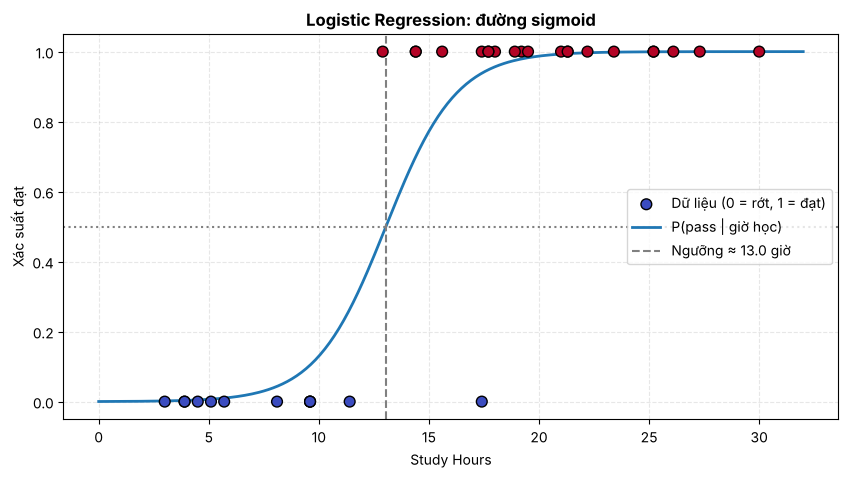

In [15]:
sh = pd.read_csv(data_path("studyhours.csv"))
sh["Pass"] = (sh["Exam Score"] >= 70).astype(int)
print(sh["Pass"].value_counts())

Xs = sh[["Study Hours"]].to_numpy()
ys = sh["Pass"].to_numpy()
sig_clf = LogisticRegression().fit(Xs, ys)
w, b = sig_clf.coef_[0][0], sig_clf.intercept_[0]
threshold_hours = -b / w   # điểm mà P(pass) = 0.5
print(f"w = {w:.3f}, b = {b:.3f} → cần khoảng {threshold_hours:.1f} giờ học để P(pass) = 0.5")
print(f"Training accuracy: {sig_clf.score(Xs, ys):.3f}")

x_grid = np.linspace(0, 32, 300).reshape(-1, 1)
plt.figure(figsize=(10, 5))
plt.scatter(Xs, ys, c=ys, cmap="coolwarm", edgecolor="black", s=60, zorder=3, label="Dữ liệu (0 = rớt, 1 = đạt)")
plt.plot(x_grid, sig_clf.predict_proba(x_grid)[:, 1], color="#1f77b4", linewidth=2, label="P(pass | giờ học)")
plt.axhline(0.5, color="gray", linestyle=":")
plt.axvline(threshold_hours, color="gray", linestyle="--", label=f"Ngưỡng ≈ {threshold_hours:.1f} giờ")
plt.xlabel("Study Hours")
plt.ylabel("Xác suất đạt")
plt.title("Logistic Regression: đường sigmoid", weight="bold")
plt.legend(loc="center right")
plt.grid(linestyle="--", alpha=0.3)
plt.show()

# Phần 2. Naive Bayes Classification

## 2.1 Ví dụ nhỏ

`CountVectorizer` biến mỗi câu thành vector đếm số lần xuất hiện của từng từ; `MultinomialNB` tính xác suất spam dựa trên tần suất từ (với làm trơn Laplace `alpha=1`).

In [16]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

emails = ["win free money now", "free prize claim now",
          "cheap money offer win", "meeting schedule for monday",
          "lunch with the team", "project report for monday"]
labels = [1, 1, 1, 0, 0, 0]   # 1 = spam

vec = CountVectorizer()
nb = MultinomialNB(alpha=1).fit(vec.fit_transform(emails), labels)

print("Từ điển:", vec.get_feature_names_out())
for s in ["free money", "team meeting on monday", "free lunch with the team"]:
    print(f"{s!r:30} P(spam) = {nb.predict_proba(vec.transform([s]))[0, 1]:.3f}")
# 'free lunch with the team' chỉ có 1 từ "spammy" nên vẫn được xếp là không spam

Từ điển: ['cheap' 'claim' 'for' 'free' 'lunch' 'meeting' 'monday' 'money' 'now'
 'offer' 'prize' 'project' 'report' 'schedule' 'team' 'the' 'win' 'with']
'free money'                   P(spam) = 0.900
'team meeting on monday'       P(spam) = 0.077
'free lunch with the team'     P(spam) = 0.158


## 2.2 Ví dụ thực tế: phân loại email spam

In [17]:
email_df = pd.read_csv(data_path("spam_or_not_spam.csv"))
print("Shape:", email_df.shape)
email_df.head()

Shape: (3000, 2)


,email,label
0,date wed NUMBER aug NUMBER NUMBER NUMBER NUMB...,0
1,martin a posted tassos papadopoulos the greek ...,0
2,man threatens explosion in moscow thursday aug...,0
3,klez the virus that won t die already the most...,0
4,in adding cream to spaghetti carbonara which ...,0


In [18]:
print(email_df.isna().sum())
email_df = email_df.dropna()
email_df["label"].value_counts()

email    1
label    0
dtype: int64


label
0    2500
1     499
Name: count, dtype: int64

In [19]:
# Độ dài email (số từ) theo nhãn
email_df["n_words"] = email_df["email"].str.split().str.len()
email_df.groupby("label")["n_words"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,2500.0,215.8,517.0,1.0,63.0,127.0,229.0,13303.0
1,499.0,336.9,741.4,0.0,90.0,162.0,331.0,11599.0


Dữ liệu **mất cân bằng**: ~83% email thường, ~17% spam. Một mô hình luôn đoán "không spam" đã đạt 83% accuracy → cần xem thêm precision/recall của lớp spam.

## 2.3 Huấn luyện và đánh giá (Model Evaluation)

In [20]:
emails = email_df["email"]
labels = email_df["label"]

email_train, email_test, label_train, label_test = train_test_split(
    emails, labels, test_size=0.2, stratify=labels, random_state=RANDOM_STATE)

vec = CountVectorizer()
X_train_txt = vec.fit_transform(email_train)   # chỉ fit trên tập train
X_test_txt = vec.transform(email_test)
print("Kích thước từ điển:", len(vec.vocabulary_))

nb = MultinomialNB(alpha=1).fit(X_train_txt, label_train)

Kích thước từ điển: 31687


Baseline (luôn đoán 'không spam'): 83.33%
Naive Bayes accuracy             : 98.83%

              precision    recall  f1-score   support

         Ham      0.986     1.000     0.993       500
        Spam      1.000     0.930     0.964       100

    accuracy                          0.988       600
   macro avg      0.993     0.965     0.978       600
weighted avg      0.988     0.988     0.988       600



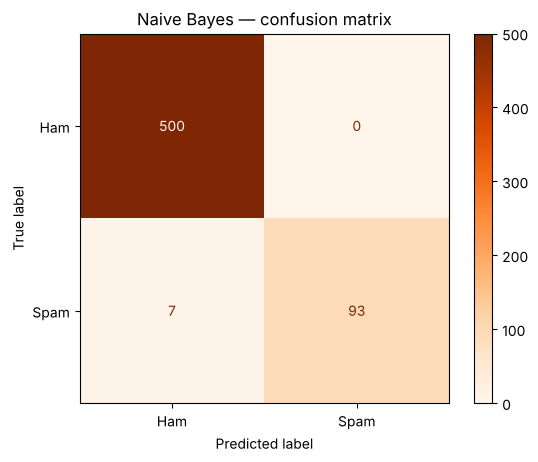

In [21]:
# Dự đoán cả tập test một lần (vector hoá), không cần vòng lặp
pred_test = nb.predict(X_test_txt)

baseline_acc = (label_test == 0).mean()
print(f"Baseline (luôn đoán 'không spam'): {baseline_acc*100:.2f}%")
print(f"Naive Bayes accuracy             : {accuracy_score(label_test, pred_test)*100:.2f}%\n")
print(classification_report(label_test, pred_test, target_names=["Ham", "Spam"], digits=3))

ConfusionMatrixDisplay.from_predictions(label_test, pred_test, display_labels=["Ham", "Spam"], cmap="Oranges")
plt.title("Naive Bayes — confusion matrix")
plt.show()

In [22]:
# Thử một vài câu mới
for s in ["free money", "team meeting on monday", "free lunch with the team",
          "click here to claim your free prize now"]:
    print(f"{s!r:45} P(spam) = {nb.predict_proba(vec.transform([s]))[0, 1]:.3f}")

'free money'                                  P(spam) = 0.873
'team meeting on monday'                      P(spam) = 0.003
'free lunch with the team'                    P(spam) = 0.380
'click here to claim your free prize now'     P(spam) = 0.991


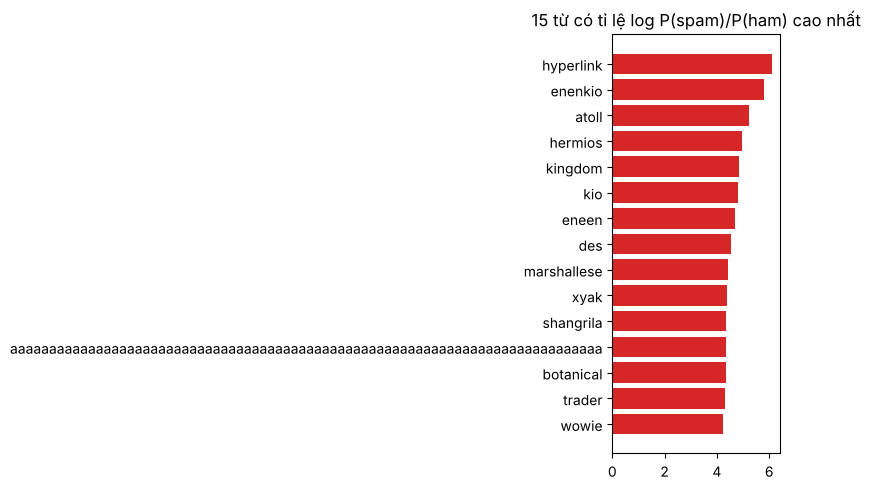

In [23]:
# Các từ "đặc trưng cho spam" nhất: log P(từ|spam) - log P(từ|ham)
vocab = vec.get_feature_names_out()
log_ratio = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
top = np.argsort(log_ratio)[-15:]
plt.figure(figsize=(8, 5))
plt.barh(vocab[top], log_ratio[top], color="#d62728")
plt.title("15 từ có tỉ lệ log P(spam)/P(ham) cao nhất")
plt.tight_layout()
plt.show()

## 2.4 So sánh với TF-IDF + Logistic Regression

Dùng cross-validation 5-fold để so sánh công bằng giữa các mô hình.

In [24]:
models = {
    "Count + MultinomialNB": make_pipeline(CountVectorizer(), MultinomialNB(alpha=1)),
    "TF-IDF + MultinomialNB": make_pipeline(TfidfVectorizer(), MultinomialNB(alpha=0.1)),
    "TF-IDF + LogisticRegression": make_pipeline(TfidfVectorizer(),
                                                 LogisticRegression(max_iter=1000, class_weight="balanced")),
}
rows = []
for name, model in models.items():
    acc = cross_val_score(model, emails, labels, cv=5, scoring="accuracy")
    f1 = cross_val_score(model, emails, labels, cv=5, scoring="f1")
    rows.append({"Model": name, "Accuracy": acc.mean(), "F1 (spam)": f1.mean()})
pd.DataFrame(rows).set_index("Model").round(4)

,Accuracy,F1 (spam)
Model,,
Count + MultinomialNB,0.9817,0.9425
TF-IDF + MultinomialNB,0.9723,0.9076
TF-IDF + LogisticRegression,0.9830,0.9470


## Tổng kết

| Bài toán | Mô hình | Nhận xét |
|---|---|---|
| Student pass/fail | Logistic Regression | ≈ baseline 50% — dữ liệu không có tín hiệu |
| Study hours → pass | Logistic Regression | Đường sigmoid tách rõ, ngưỡng ≈ số giờ in ở trên |
| Spam email | Naive Bayes | Accuracy cao hơn hẳn baseline 83%; xem F1 của lớp spam |

Bài học chính: **accuracy một mình không đủ** — cần so với baseline, và với dữ liệu mất cân bằng cần xem precision, recall, F1.